## Analysing threats and business impacts in the CISA scenarios (Goal 1)

Each scenario event from the eight CISA manuals is labelled with a threat type and a business impact, grouped into broader categories, and the relationship between threats and impacts is examined.

**What changed compared to the previous version:**
- **The data path is relative to the project folder** (`../data/processed`) instead of a path on one person's computer (`C:\Users\...`), so the notebook runs for every team member.
- **"Five manuals" corrected to eight.**
- **The labelling rules are written down** (step 4), so the manual annotation can be explained and checked.
- **Extra checks** that every label is filled in and every threat type has a category (step 6).
- **The threat × impact table is also drawn as a heatmap** (step 11), which is easier to read in the report.
- The labels themselves (`annotations`, `threat_groups`, `impact_groups`) are **unchanged**, so `cisa_classified_events.csv` is identical to before.

#### 1. Loading the data
The extracted scenario events from the eight CISA manuals are loaded from a CSV file.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path("../data/processed")
if not data_dir.exists():
    data_dir = Path("data/processed")

df_injects = pd.read_csv(data_dir / "cisa_scenario_injects.csv")

print("Events:", df_injects.shape)

Events: (66, 6)


#### 2. Inspecting the events
The scenario descriptions are displayed to check that the extracted information looks correct.

In [2]:
pd.set_option("display.max_colwidth", None)

display(df_injects[
    ["inject_id", "manual_title", "section", "day", "event_description"]
])

,inject_id,manual_title,section,day,event_description
0,HC-INJ-87,Healthcare,Module 1,Day 1,"The Cybersecurity and Infrastructure Security Agency (CISA), the Federal Bureau of Investigation (FBI), and the Department of Health and Human Services (HHS) Health Sector Cybersecurity Coordination Center (HC3) release a joint alert regarding a rise in cyberattacks targeting healthcare organizations. The alert describes the tactics, techniques, and procedures (TTPs) used by cyber criminals, including phishing emails, ransomware, remote hacking, distributed denial of service (DDoS) attacks, and data exfiltration from healthcare organizations."
1,HC-INJ-89,Healthcare,Module 1,Day 9,"<Organization> employees receive e-mail notifications from your managed service provider (MSP) requesting they update their profiles prior to the launch of a new human resources (HR) system. The e-mail contains a link and attachment named Update_Form.docx. Employees working at remote workstations across facilities click the link and are asked to log into their web portal. Upon logging in, they are brought to a 404 Error Page. Some employees also open the attachment and click to allow macros to run."
2,HC-INJ-117,Healthcare,Module 1,Day 10,Manufacturer’s updates are pushed for installation on patient monitors. The updates are downloaded from the manufacturer’s website and installed without issue.
3,HC-INJ-119,Healthcare,Module 1,Day 13,"A third-party electronic medical record (EMR) vendor shows up unannounced at your facility to update equipment. The vendor needs to patch a recently discovered vulnerability in software used on several devices, including workstations, imaging and radiology equipment, bedside monitors, and other clinical devices."
4,HC-INJ-126,Healthcare,Module 1,Day 15,"Radiology reports an issue with their Magnetic Resonance Imaging (MRI) machine accepting patient information, stating their computer is locking up or taking a long time to load. The reports also indicate an extraordinary amount of time is required to pull images for each patient. The delays have resulted in patient appointments running more than two hours behind schedule."
...,...,...,...,...,...
61,CM-INJ-114,Communications,Module 1,Day 24,Customers call your customer service and technical support lines complaining of service issues. Many state they are unable to reach any websites while others complain of receiving slower access speeds than promised.
62,CM-INJ-120,Communications,Module 2,Day 43 – Early Morning,"Your organization receives several million illegitimate web requests per second (RPS), preventing your servers from authorizing legitimate requests. The resulting DDoS limits the ability to provide services to your customers, including local Emergency Communications Centers (ECCs)/Public Safety Answering Points (PSAPs)/9-1-1 Call Centers and other critical infrastructure owners."
63,CM-INJ-135,Communications,Module 2,Day 43 – Mid Morning,Customers cannot access the internet because of the DDoS attack and inundate your call center with complaints. Many customers refuse to hang-up until their service is restored. The volume of customer calls overwhelms the call center and results in a Telecom Denial of Service (TDoS).
64,CM-INJ-141,Communications,Module 2,Day 43 – Evening,"The DDoS subsides; however, the issues your organization and customers faced gain media attention. Local news outlets reach out to multiple customers and the local emergency management agency director. All customers interviewed voice concern over the service disruption the community faced during the event."


#### 3. Checking the data
The dataset is checked for missing values, duplicates, and short descriptions. Event counts are also compared across the manuals.

The two missing `day` values are expected: the Executives manual uses vignettes without scenario days.

In [3]:
print("Missing values:")
print(df_injects.isna().sum())

print("\nDuplicate IDs:", df_injects["inject_id"].duplicated().sum())
print("Duplicate descriptions:", df_injects["event_description"].duplicated().sum())

short_events = df_injects[df_injects["event_description"].str.len() < 100]
print("\nDescriptions under 100 characters:", len(short_events))

print("\nEvents per manual:")
print(df_injects["manual_title"].value_counts())

print("\nEvents per section:")
display(
    df_injects.groupby(["manual_title", "section"])
    .size()
    .reset_index(name="event_count")
)

Missing values:
manual_title         0
inject_id            0
section              0
day                  2
event_description    0
source_paragraph     0
dtype: int64

Duplicate IDs: 0
Duplicate descriptions: 0

Descriptions under 100 characters: 0

Events per manual:
manual_title
Insider Threat                12
Healthcare                    11
Industrial Control Systems     9
Vendor                         8
Ransomware                     8
Financial Services             8
Communications                 8
Executives                     2
Name: count, dtype: int64

Events per section:


,manual_title,section,event_count
0,Communications,Module 1,4
1,Communications,Module 2,4
2,Executives,Vignette 1: Whaling/Ransomware,1
3,Executives,Vignette 2: Insider Threat,1
4,Financial Services,Module 1,4
5,Financial Services,Module 2,4
6,Healthcare,Module 1,5
7,Healthcare,Module 2,6
8,Industrial Control Systems,Module 1,5
9,Industrial Control Systems,Module 2,4


#### 4. Classifying the events
Each scenario event is assigned a threat type and a description of its business consequences, based on reading the event in the CISA manual (manual expert annotation).

**Labelling rules:**
- The **threat type** describes the incident the event belongs to. Follow-up events (e.g. media attention after a ransomware attack, customers withdrawing money during a banking outage) get the threat type of that incident.
- Events where no attack takes place (alerts, routine updates, workplace conflict) are labelled *Security Alert*, *No Specific Threat* or *No Specific Cyber Threat*.
- The **business impact** describes what actually happens to the organization in that event, in one sentence. Where nothing has happened yet, it says so ("No direct impact reported; ...").

In [4]:
df_labeled = df_injects.copy()

annotations = {
    # HEALTHCARE: 11 events
    "HC-INJ-87": (
        "Security Alert",
        "No direct impact reported; increased awareness of threats targeting healthcare organizations"
    ),
    "HC-INJ-89": (
        "Suspected Phishing",
        "Potential credential theft and malware infection through suspicious emails and attachments"
    ),
    "HC-INJ-117": (
        "No Specific Threat",
        "No negative impact reported; patient monitor updates installed successfully"
    ),
    "HC-INJ-119": (
        "Vulnerability Exposure",
        "Potential compromise of clinical devices and systems if the vulnerability remains unpatched"
    ),
    "HC-INJ-126": (
        "System Disruption (Unconfirmed Cause)",
        "MRI system delays causing patient appointments to run more than two hours behind schedule"
    ),
    "HC-INJ-135": (
        "Unauthorized Access Risk",
        "Potential misuse of former employees' active IT accounts; accounts were deactivated"
    ),
    "HC-INJ-137": (
        "Data Integrity Issue",
        "Incorrect patient records creating risks to patient safety and clinical decisions"
    ),
    "HC-INJ-139": (
        "Medical Device Malfunction",
        "Inaccurate monitoring data and incorrect infusion rates threatening patient safety"
    ),
    "HC-INJ-156": (
        "Ransomware",
        "Files unavailable, $1 million ransom demand, and threatened exposure of patient data"
    ),
    "HC-INJ-159": (
        "Data Breach",
        "Patient information exposed; extortion attempts, complaints, and threatened legal action"
    ),
    "HC-INJ-163": (
        "Data Breach",
        "Loss of patient trust, requests for hospital transfers, and potential loss of patients"
    ),

    # VENDOR SUPPLY CHAIN: 8 events
    "VD-INJ-111": (
        "Supply Chain Compromise",
        "Global service disruptions affecting MSP customers; no direct impact on the organization"
    ),
    "VD-INJ-122": (
        "No Specific Threat",
        "No negative impact reported during onboarding of a new managed service provider"
    ),
    "VD-INJ-136": (
        "Third-Party Data Breach",
        "Partner data exposed; possible concerns about the security of the new MSP"
    ),
    "VD-INJ-143": (
        "No Specific Threat",
        "No negative impact reported; authorized software update intended to improve functionality"
    ),
    "VD-INJ-150": (
        "System Disruption (Unconfirmed Cause)",
        "Employees unable to access the network; MSP support unavailable"
    ),
    "VD-INJ-152": (
        "System Disruption (Unconfirmed Cause)",
        "Continued network outage significantly affecting business-critical systems"
    ),
    "VD-INJ-162": (
        "Supply Chain Compromise",
        "MSP platform compromised; potential malware exposure affecting customers"
    ),
    "VD-INJ-167": (
        "Suspicious Network Activity",
        "Possible network compromise requiring investigation; full impact not yet established"
    ),

    # RANSOMWARE: 8 events
    "RW-INJ-84": (
        "Security Alert",
        "No direct impact reported; warning about a new ransomware campaign"
    ),
    "RW-INJ-86": (
        "Vulnerability Exposure",
        "Increased security risk because the operating system no longer receives security patches"
    ),
    "RW-INJ-88": (
        "Device Theft",
        "Potential exposure of sensitive organizational information stored on a stolen laptop"
    ),
    "RW-INJ-90": (
        "Suspected Phishing",
        "Potential malware infection or unauthorized access after employees opened a suspicious PDF"
    ),
    "RW-INJ-122": (
        "Suspected Data Exfiltration",
        "Significant data transferred to external IP addresses; possible exposure of sensitive information"
    ),
    "RW-INJ-124": (
        "Ransomware",
        "Computers locked by ransomware, disrupting operations and triggering a ransom demand"
    ),
    "RW-INJ-126": (
        "Data Breach",
        "Employee personal and financial information exposed; threatened sale of stolen data"
    ),
    "RW-INJ-128": (
        "Ransomware",
        "Media attention following the ransomware incident and data breach; reputational risk"
    ),

    # INSIDER THREAT: 12 events
    "IT-INJ-85": (
        "Vulnerability Exposure",
        "Potential unauthorized access to sensitive data through a microprocessor vulnerability"
    ),
    "IT-INJ-87": (
        "Vulnerability Exposure",
        "Costly and time-consuming hardware replacement; security risk remains during rollout"
    ),
    "IT-INJ-89": (
        "Accidental Data Disclosure",
        "Personally identifiable information accidentally disclosed to external contacts"
    ),
    "IT-INJ-91": (
        "No Specific Cyber Threat",
        "Workplace conflict following the PII disclosure; potential personnel consequences"
    ),
    "IT-INJ-93": (
        "Potential Insider Threat",
        "Risk of retaliation from a terminated employee; no cyberattack established at this stage"
    ),
    "IT-INJ-121": (
        "Vulnerability Exposure",
        "Extended security exposure and resource demands due to an 18-month replacement process"
    ),
    "IT-INJ-123": (
        "Potential Insider Threat",
        "Possible third-party access risk involving a former employee; no incident confirmed"
    ),
    "IT-INJ-125": (
        "Unauthorized File Modification",
        "Files moved or deleted; lost work since the last backup"
    ),
    "IT-INJ-127": (
        "Unauthorized Access",
        "Unauthorized administrator account discovered and deactivated; potential system compromise"
    ),
    "IT-INJ-129": (
        "Unauthorized Access",
        "Administrator credentials compromised, enabling privileged access and lateral movement"
    ),
    "IT-INJ-131": (
        "Suspicious Third-Party Activity",
        "Unauthorized account creation traced to a vendor-associated IP address; responsibility unconfirmed"
    ),
    "IT-INJ-133": (
        "Unauthorized File Deletion",
        "Critical organizational files appear deleted, threatening core business operations"
    ),

    # EXECUTIVES AND SENIOR LEADERSHIP: 2 events
    "EX-INJ-109": (
        "Whaling / Ransomware",
        "Payroll disruption, employee computer lockouts, ransom demand, and exposure of bank account information"
    ),
    "EX-INJ-126": (
        "Insider Threat",
        "Sensitive information stolen, including intellectual property; external data exposure and reputational risk"
    ),

        # INDUSTRIAL CONTROL SYSTEMS: 9 events
    "ICS-INJ-90": (
        "Security Alert",
        "No direct impact reported; warning about attacks targeting industrial control systems"
    ),
    "ICS-INJ-102": (
        "No Specific Threat",
        "No direct impact reported; cloud modernization and remote access introduce potential security risks"
    ),
    "ICS-INJ-116": (
        "Suspected Phishing",
        "Employees followed a suspicious link; potential credential compromise"
    ),
    "ICS-INJ-118": (
        "Unauthorized Access Risk",
        "Some employees approved unexpected MFA requests; potential unauthorized account access"
    ),
    "ICS-INJ-129": (
        "Suspicious Third-Party Activity",
        "Equipment appears to have been installed without the scheduled vendor; possible unauthorized physical access"
    ),
    "ICS-INJ-139": (
        "System Disruption (Unconfirmed Cause)",
        "Service disruptions and distorted system data affecting equipment monitoring"
    ),
    "ICS-INJ-146": (
        "Suspected Ransomware",
        "Industrial operations shut down, control data encrypted, and employees locked out of accounts"
    ),
    "ICS-INJ-165": (
        "Extortion Threat",
        "Threat of continued IT and OT system lockouts and disruption of industrial processes"
    ),
    "ICS-INJ-167": (
        "Data Breach",
        "Sensitive information offered for sale; vulnerabilities used to compromise IT and OT systems"
    ),

        # Financial Services
    "FS-INJ-83": (
        "Security Alert",
        "No direct impact on the organization reported; other financial institutions have experienced data theft through their service providers"
    ),
    "FS-INJ-98": (
        "Suspected Phishing",
        "Employees attempted to open a fraudulent invoice attachment; potential security compromise"
    ),
    "FS-INJ-110": (
        "Data Breach",
        "Cloud services unavailable and customer data stolen"
    ),
    "FS-INJ-119": (
        "Data Breach",
        "Significant amounts of customer data stolen from cloud systems"
    ),
    "FS-INJ-123": (
        "Ransomware",
        "Internal and online banking systems unavailable; $5 million ransom demand"
    ),
    "FS-INJ-133": (
        "Ransomware",
        "Customers unable to access banking services and demanding withdrawals"
    ),
    "FS-INJ-141": (
        "Ransomware",
        "Regional banking outages receive national media coverage, creating reputational concerns"
    ),
    "FS-INJ-150": (
        "Ransomware",
        "Customers attempt to withdraw funds and close accounts because of continued banking outages"
    ),

        # Communications
    "CM-INJ-83": (
        "Security Alert",
        "No direct impact reported; warning about attacks targeting internet providers"
    ),
    "CM-INJ-95": (
        "Suspected Phishing",
        "Employees followed a suspicious link and were instructed to download a file; potential security compromise"
    ),
    "CM-INJ-108": (
        "Security Alert",
        "No direct impact reported; possible cyber-related outages at other telecommunications providers"
    ),
    "CM-INJ-114": (
        "System Disruption (Unconfirmed Cause)",
        "Customers experience slow internet speeds and loss of internet access"
    ),
    "CM-INJ-120": (
        "DDoS",
        "Broadband services disrupted, including services for emergency communications and critical infrastructure customers"
    ),
    "CM-INJ-135": (
        "DDoS / Unintentional TDoS",
        "Internet outages continue and customer calls overwhelm the support center"
    ),
    "CM-INJ-141": (
        "DDoS",
        "Service disruptions receive media attention and customers express concerns"
    ),
    "CM-INJ-147": (
        "DDoS",
        "Investigation identifies approximately one million devices used in the earlier attack; no new disruption reported"
    )
}

# Check that every event has a matching annotation
assert set(df_labeled["inject_id"]) == set(annotations)

# Assign threat types and business impacts
df_labeled["threat_type"] = df_labeled["inject_id"].map(lambda x: annotations[x][0])
df_labeled["business_impact"] = df_labeled["inject_id"].map(lambda x: annotations[x][1])

display(df_labeled[["inject_id", "manual_title", "threat_type", "business_impact"]])

,inject_id,manual_title,threat_type,business_impact
0,HC-INJ-87,Healthcare,Security Alert,No direct impact reported; increased awareness of threats targeting healthcare organizations
1,HC-INJ-89,Healthcare,Suspected Phishing,Potential credential theft and malware infection through suspicious emails and attachments
2,HC-INJ-117,Healthcare,No Specific Threat,No negative impact reported; patient monitor updates installed successfully
3,HC-INJ-119,Healthcare,Vulnerability Exposure,Potential compromise of clinical devices and systems if the vulnerability remains unpatched
4,HC-INJ-126,Healthcare,System Disruption (Unconfirmed Cause),MRI system delays causing patient appointments to run more than two hours behind schedule
...,...,...,...,...
61,CM-INJ-114,Communications,System Disruption (Unconfirmed Cause),Customers experience slow internet speeds and loss of internet access
62,CM-INJ-120,Communications,DDoS,"Broadband services disrupted, including services for emergency communications and critical infrastructure customers"
63,CM-INJ-135,Communications,DDoS / Unintentional TDoS,Internet outages continue and customer calls overwhelm the support center
64,CM-INJ-141,Communications,DDoS,Service disruptions receive media attention and customers express concerns


#### 5. Grouping threat types
Similar threat types are grouped into broader categories to make them easier to compare and analyze.

In [5]:
threat_groups = {
    "Ransomware": "Ransomware",
    "Whaling / Ransomware": "Ransomware",
    "Suspected Ransomware": "Ransomware",
    "Extortion Threat": "Ransomware",

    "Suspected Phishing": "Phishing",

    "Insider Threat": "Insider Threat / Unauthorized Access",
    "Potential Insider Threat": "Insider Threat / Unauthorized Access",
    "Unauthorized Access": "Insider Threat / Unauthorized Access",
    "Unauthorized Access Risk": "Insider Threat / Unauthorized Access",
    "Unauthorized File Modification": "Insider Threat / Unauthorized Access",
    "Unauthorized File Deletion": "Insider Threat / Unauthorized Access",

    "Supply Chain Compromise": "Third-Party / Supply Chain",
    "Third-Party Data Breach": "Third-Party / Supply Chain",
    "Suspicious Third-Party Activity": "Third-Party / Supply Chain",

    "Data Breach": "Data Exposure",
    "Accidental Data Disclosure": "Data Exposure",
    "Suspected Data Exfiltration": "Data Exposure",

    "Vulnerability Exposure": "Vulnerability",

    "System Disruption (Unconfirmed Cause)": "System Disruption",
    "Medical Device Malfunction": "System Disruption",

    "Data Integrity Issue": "Other Security Incident",
    "Device Theft": "Other Security Incident",
    "Suspicious Network Activity": "Other Security Incident",

    "Security Alert": "No Confirmed Incident",
    "No Specific Threat": "No Confirmed Incident",
    "No Specific Cyber Threat": "No Confirmed Incident", 

    "DDoS": "Denial of Service",
    "DDoS / Unintentional TDoS": "Denial of Service",
}

df_labeled["threat_category"] = df_labeled["threat_type"].map(threat_groups)

assert df_labeled["threat_category"].notna().all()

display(df_labeled[["inject_id", "threat_type", "threat_category"]])

,inject_id,threat_type,threat_category
0,HC-INJ-87,Security Alert,No Confirmed Incident
1,HC-INJ-89,Suspected Phishing,Phishing
2,HC-INJ-117,No Specific Threat,No Confirmed Incident
3,HC-INJ-119,Vulnerability Exposure,Vulnerability
4,HC-INJ-126,System Disruption (Unconfirmed Cause),System Disruption
...,...,...,...
61,CM-INJ-114,System Disruption (Unconfirmed Cause),System Disruption
62,CM-INJ-120,DDoS,Denial of Service
63,CM-INJ-135,DDoS / Unintentional TDoS,Denial of Service
64,CM-INJ-141,DDoS,Denial of Service


#### 6. Checking the labels
Every event must have a threat type, a business impact and a threat category.

*Why:* the labels are typed by hand, so a typo in a threat type name would silently give an event no category. These checks stop the notebook if that happens.

In [6]:
assert df_labeled["threat_type"].notna().all()
assert df_labeled["business_impact"].str.strip().str.len().gt(0).all(), "Empty business impact"

unknown_types = set(df_labeled["threat_type"]) - set(threat_groups)
assert not unknown_types, f"Threat types without a category: {unknown_types}"

unused_types = set(threat_groups) - set(df_labeled["threat_type"])
print("Threat types:", df_labeled["threat_type"].nunique(),
      "| categories:", df_labeled["threat_category"].nunique())
print("Unused threat types in the grouping table:", unused_types or "none")

Threat types: 28 | categories: 10
Unused threat types in the grouping table: none


#### 7. Examining threat types
The number of events in each threat category is compared.

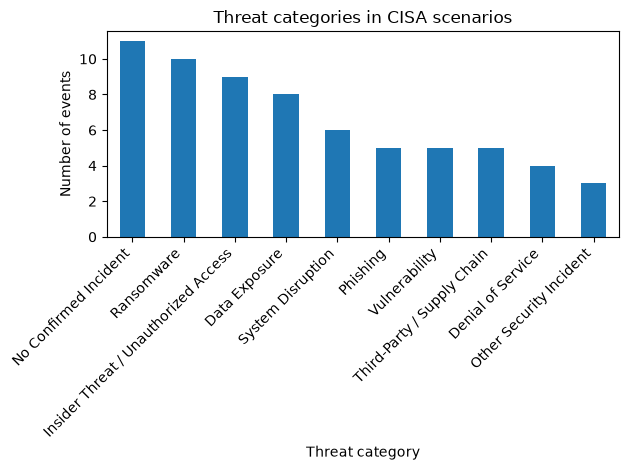

In [7]:
df_labeled["threat_category"].value_counts().plot(kind="bar")

plt.title("Threat categories in CISA scenarios")
plt.xlabel("Threat category")
plt.ylabel("Number of events")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### 8. Grouping business impacts
Business consequences are grouped into broader categories to compare the effects of different cybersecurity threats.

In [8]:
impact_groups = {
    # Healthcare
    "HC-INJ-87": "No Direct Impact",
    "HC-INJ-89": "Security Risk",
    "HC-INJ-117": "No Direct Impact",
    "HC-INJ-119": "Security Risk",
    "HC-INJ-126": "Operational Disruption",
    "HC-INJ-135": "Security Risk",
    "HC-INJ-137": "Patient Safety",
    "HC-INJ-139": "Patient Safety",
    "HC-INJ-156": "Operational Disruption",
    "HC-INJ-159": "Data Exposure",
    "HC-INJ-163": "Reputational Damage",

    # Vendor
    "VD-INJ-111": "No Direct Impact",
    "VD-INJ-122": "No Direct Impact",
    "VD-INJ-136": "Data Exposure",
    "VD-INJ-143": "No Direct Impact",
    "VD-INJ-150": "Operational Disruption",
    "VD-INJ-152": "Operational Disruption",
    "VD-INJ-162": "Security Risk",
    "VD-INJ-167": "Security Risk",

    # Ransomware
    "RW-INJ-84": "No Direct Impact",
    "RW-INJ-86": "Security Risk",
    "RW-INJ-88": "Security Risk",
    "RW-INJ-90": "Security Risk",
    "RW-INJ-122": "Data Exposure",
    "RW-INJ-124": "Operational Disruption",
    "RW-INJ-126": "Data Exposure",
    "RW-INJ-128": "Reputational Damage",

    # Insider Threat
    "IT-INJ-85": "Security Risk",
    "IT-INJ-87": "Financial Cost",
    "IT-INJ-89": "Data Exposure",
    "IT-INJ-91": "Personnel Consequences",
    "IT-INJ-93": "Security Risk",
    "IT-INJ-121": "Financial Cost",
    "IT-INJ-123": "Security Risk",
    "IT-INJ-125": "Data Loss",
    "IT-INJ-127": "Security Risk",
    "IT-INJ-129": "Security Risk",
    "IT-INJ-131": "Security Risk",
    "IT-INJ-133": "Data Loss",

    # Executives
    "EX-INJ-109": "Operational Disruption",
    "EX-INJ-126": "Data Exposure",

    # Industrial Control Systems
    "ICS-INJ-90": "No Direct Impact",
    "ICS-INJ-102": "No Direct Impact",
    "ICS-INJ-116": "Security Risk",
    "ICS-INJ-118": "Security Risk",
    "ICS-INJ-129": "Security Risk",
    "ICS-INJ-139": "Operational Disruption",
    "ICS-INJ-146": "Operational Disruption",
    "ICS-INJ-165": "Operational Disruption",
    "ICS-INJ-167": "Data Exposure",

    # Financial Services
    "FS-INJ-83": "No Direct Impact",
    "FS-INJ-98": "Security Risk",
    "FS-INJ-110": "Operational Disruption",
    "FS-INJ-119": "Data Exposure",
    "FS-INJ-123": "Operational Disruption",
    "FS-INJ-133": "Operational Disruption",
    "FS-INJ-141": "Reputational Damage",
    "FS-INJ-150": "Reputational Damage",

    # Communications
    "CM-INJ-83": "No Direct Impact",
    "CM-INJ-95": "Security Risk",
    "CM-INJ-108": "No Direct Impact",
    "CM-INJ-114": "Operational Disruption",
    "CM-INJ-120": "Operational Disruption",
    "CM-INJ-135": "Operational Disruption",
    "CM-INJ-141": "Reputational Damage",
    "CM-INJ-147": "No Direct Impact"
}

assert set(df_labeled["inject_id"]) == set(impact_groups)

df_labeled["impact_category"] = df_labeled["inject_id"].map(impact_groups)

display(df_labeled[
    ["inject_id", "business_impact", "impact_category"]
])

,inject_id,business_impact,impact_category
0,HC-INJ-87,No direct impact reported; increased awareness of threats targeting healthcare organizations,No Direct Impact
1,HC-INJ-89,Potential credential theft and malware infection through suspicious emails and attachments,Security Risk
2,HC-INJ-117,No negative impact reported; patient monitor updates installed successfully,No Direct Impact
3,HC-INJ-119,Potential compromise of clinical devices and systems if the vulnerability remains unpatched,Security Risk
4,HC-INJ-126,MRI system delays causing patient appointments to run more than two hours behind schedule,Operational Disruption
...,...,...,...
61,CM-INJ-114,Customers experience slow internet speeds and loss of internet access,Operational Disruption
62,CM-INJ-120,"Broadband services disrupted, including services for emergency communications and critical infrastructure customers",Operational Disruption
63,CM-INJ-135,Internet outages continue and customer calls overwhelm the support center,Operational Disruption
64,CM-INJ-141,Service disruptions receive media attention and customers express concerns,Reputational Damage


#### 9. Examining business consequences
The number of events in each business impact category is compared.

impact_category
Security Risk             19
Operational Disruption    15
No Direct Impact          12
Data Exposure              8
Reputational Damage        5
Patient Safety             2
Financial Cost             2
Data Loss                  2
Personnel Consequences     1
Name: count, dtype: int64


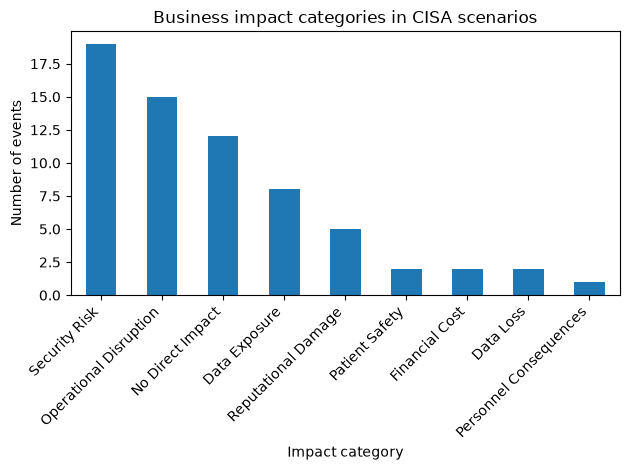

In [9]:
print(df_labeled["impact_category"].value_counts())

df_labeled["impact_category"].value_counts().plot(kind="bar")
plt.title("Business impact categories in CISA scenarios")
plt.xlabel("Impact category")
plt.ylabel("Number of events")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### 10. Saving the results
The classified events and their threat and impact categories are saved for further analysis.

In [10]:
assert len(df_labeled) == 66

assert df_labeled[
    ["threat_type", "business_impact",
     "threat_category", "impact_category"]
].notna().all().all()

df_labeled.to_csv(
    data_dir / "cisa_classified_events.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Classified events saved:", len(df_labeled))

Classified events saved: 66


#### 11. Comparing threats and business impacts
The relationship between threat categories and business impacts is examined as a table and as a heatmap.

*Why:* this is the main Goal 1 result: which threats lead to which consequences for a business. The heatmap makes the pattern visible at a glance (e.g. ransomware mostly leads to operational disruption, phishing to security risk).

impact_category,Data Exposure,Data Loss,Financial Cost,No Direct Impact,Operational Disruption,Patient Safety,Personnel Consequences,Reputational Damage,Security Risk
threat_category,,,,,,,,,
Data Exposure,6,0,0,0,1,0,0,1,0
Denial of Service,0,0,0,1,2,0,0,1,0
Insider Threat / Unauthorized Access,1,2,0,0,0,0,0,0,6
No Confirmed Incident,0,0,0,10,0,0,1,0,0
Other Security Incident,0,0,0,0,0,1,0,0,2
Phishing,0,0,0,0,0,0,0,0,5
Ransomware,0,0,0,0,7,0,0,3,0
System Disruption,0,0,0,0,5,1,0,0,0
Third-Party / Supply Chain,1,0,0,1,0,0,0,0,3


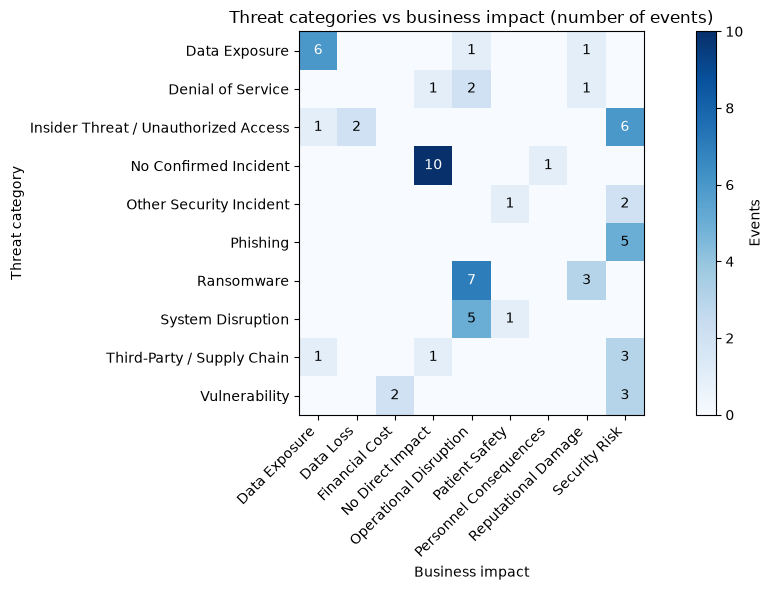

In [11]:
crosstab = pd.crosstab(df_labeled["threat_category"], df_labeled["impact_category"])
display(crosstab)

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(crosstab.values, cmap="Blues")

ax.set_xticks(range(len(crosstab.columns)))
ax.set_xticklabels(crosstab.columns, rotation=45, ha="right")
ax.set_yticks(range(len(crosstab.index)))
ax.set_yticklabels(crosstab.index)

for i in range(crosstab.shape[0]):
    for j in range(crosstab.shape[1]):
        value = crosstab.values[i, j]
        if value:
            ax.text(j, i, value, ha="center", va="center",
                    color="white" if value > crosstab.values.max() / 2 else "black")

ax.set_title("Threat categories vs business impact (number of events)")
ax.set_xlabel("Business impact")
ax.set_ylabel("Threat category")
fig.colorbar(im, ax=ax, label="Events")
plt.tight_layout()
plt.show()